In [3]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path

import sys
import json
import gc
import time
import hashlib
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from sklearn.metrics import (
    ConfusionMatrixDisplay
)

In [4]:
PROJECT_DIR = Path(r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca")

DATASET_DIR = (
    PROJECT_DIR
    / "dataset"
    / "raw"
    / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"

REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR = PROJECT_DIR / "models"

LOGS_DIR = PROJECT_DIR / "logs"

EXPERIMENTS_DIR = PROJECT_DIR / "experiments"

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(PROJECT_DIR)
    )

In [5]:
from src.utils import (
    set_seed,
    get_device
)

from src.preprocessing import (
    build_transforms
)

from src.model_factory import (
    MODEL_REGISTRY,
    create_model
)

from src.experiments import (
    run_training_experiment,
    release_memory,
    save_json
)

In [6]:
def load_json(filepath):

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as f:

        return json.load(f)


dataset_config = load_json(
    CONFIGS_DIR / "dataset_config.json"
)

training_config = load_json(
    CONFIGS_DIR / "training_config.json"
)

model_config = load_json(
    CONFIGS_DIR / "model_config.json"
)

pipeline_config = load_json(
    CONFIGS_DIR / "pipeline_config.json"
)

preprocessing_config = load_json(
    CONFIGS_DIR / "preprocessing_config.json"
)

SEED = dataset_config["seed"]

CLASS_MAPPING = dataset_config["class_mapping"]

NUM_CLASSES = len(CLASS_MAPPING)

ARCHITECTURES = training_config["architectures"]

DEVICE = get_device()

set_seed(SEED)

print("Dispositivo:", DEVICE)

print("Arquitecturas:", len(ARCHITECTURES))

print("Clases:", NUM_CLASSES)

print("Semilla:", SEED)

Dispositivo: cuda
Arquitecturas: 5
Clases: 5
Semilla: 42


In [7]:
assert torch.cuda.is_available()

assert DEVICE.type == "cuda"

assert len(ARCHITECTURES) == 5

assert len(set(ARCHITECTURES)) == 5

assert NUM_CLASSES == 5

assert torch.are_deterministic_algorithms_enabled()

assert not (
    torch.is_deterministic_algorithms_warn_only_enabled()
)

assert os.environ.get(
    "CUBLAS_WORKSPACE_CONFIG"
) in [":4096:8", ":16:8"]

print("GPU:", torch.cuda.get_device_name(0))

print(
    "CUDA:",
    torch.version.cuda
)

print(
    "Memoria GPU (GiB):",
    torch.cuda.get_device_properties(0)
    .total_memory / 1024**3
)

print("Entorno verificado.")

GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
CUDA: 12.1
Memoria GPU (GiB): 3.99951171875
Entorno verificado.


In [8]:
baseline_config = {

    "experiment_name": "baseline",

    "run_id": "baseline_v1",

    "seed": SEED,

    "validation_fold": 1,

    "architectures": ARCHITECTURES,

    "pretrained": True,

    "dropout": model_config["default_dropout"],

    "weight_decay": pipeline_config[
        "optimizer"
    ]["weight_decay"],

    "num_workers": 0,

    "effective_batch_size": 32,

    "mixed_precision": True,

    "amp": training_config[
        "training"
    ]["amp"],

    "feature_extraction": {

        "epochs": 3,

        "classifier_lr": pipeline_config[
            "feature_extraction"
        ]["classifier_lr"]

    },

    "partial_finetuning": {

        "epochs": 2,

        "classifier_lr": pipeline_config[
            "partial_finetuning"
        ]["classifier_lr"],

        "backbone_lr": pipeline_config[
            "partial_finetuning"
        ]["backbone_lr"]

    },

    "scheduler": pipeline_config["scheduler"],

    "early_stopping": pipeline_config[
        "early_stopping"
    ],

    "loss": pipeline_config["loss"],

    "selection_metric": "f1_macro",

    "remove_last_checkpoints": True,

    "test_reserved": True

}

In [9]:
BASELINE_CONFIG_PATH = (
    CONFIGS_DIR / "baseline_config.json"
)

save_json(
    baseline_config,
    BASELINE_CONFIG_PATH
)

print(
    "Configuración guardada:",
    BASELINE_CONFIG_PATH
)

Configuración guardada: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\configs\baseline_config.json


In [10]:
RUN_ID = baseline_config["run_id"]

BASELINE_MODELS_DIR = (
    MODELS_DIR / "baseline" / RUN_ID
)

BASELINE_REPORTS_DIR = (
    REPORTS_DIR / "baseline" / RUN_ID
)

BASELINE_LOGS_DIR = (
    LOGS_DIR / "baseline" / RUN_ID
)

BASELINE_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR / "baseline" / RUN_ID
)

for directory in [

    BASELINE_MODELS_DIR,

    BASELINE_REPORTS_DIR,

    BASELINE_LOGS_DIR,

    BASELINE_EXPERIMENTS_DIR

]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Directorios preparados.")

Directorios preparados.


In [11]:
def calculate_sha256(filepath):

    sha256 = hashlib.sha256()

    with open(filepath, "rb") as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            sha256.update(block)

    return sha256.hexdigest()


configuration_files = [

    "dataset_config.json",

    "preprocessing_config.json",

    "training_config.json",

    "model_config.json",

    "pipeline_config.json",

    "baseline_config.json"

]

tracked_files = [

    CONFIGS_DIR / filename

    for filename in configuration_files

]

tracked_files += [

    REPORTS_DIR / "dataset_splits.csv",

    PROJECT_DIR / "src" / "trainer.py",

    PROJECT_DIR / "src" / "experiments.py",

    PROJECT_DIR / "src" / "metrics.py",

    PROJECT_DIR / "src" / "model_factory.py",

    PROJECT_DIR / "src" / "data_generator.py",

    PROJECT_DIR / "src" / "dataset.py",

    PROJECT_DIR / "src" / "preprocessing.py",

    PROJECT_DIR / "src" / "utils.py"

]

experiment_signature = {

    str(filepath.relative_to(PROJECT_DIR)):

        calculate_sha256(filepath)

    for filepath in tracked_files

}

SIGNATURE_PATH = (
    BASELINE_EXPERIMENTS_DIR
    / "experiment_signature.json"
)

if SIGNATURE_PATH.exists():

    previous_signature = load_json(
        SIGNATURE_PATH
    )

    assert previous_signature == experiment_signature, (
        "La configuración o el código cambió. "
        "Utiliza un nuevo run_id."
    )

else:

    save_json(
        experiment_signature,
        SIGNATURE_PATH
    )

    for filename in configuration_files:

        shutil.copy2(

            CONFIGS_DIR / filename,

            BASELINE_EXPERIMENTS_DIR / filename

        )

print("Firma experimental verificada.")

AssertionError: La configuración o el código cambió. Utiliza un nuevo run_id.

In [10]:
from datetime import datetime

previous_signature = load_json(
    SIGNATURE_PATH
)

modified_files = {

    filepath

    for filepath in (
        set(previous_signature)
        | set(experiment_signature)
    )

    if previous_signature.get(filepath)
    != experiment_signature.get(filepath)

}

allowed_changes = {

    str(Path("src") / "trainer.py"),

    str(Path("src") / "experiments.py")

}

assert modified_files.issubset(
    allowed_changes
), (
    "Existen cambios no autorizados."
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

if modified_files:

    save_json(

        previous_signature,

        BASELINE_EXPERIMENTS_DIR
        / f"signature_backup_{timestamp}.json"

    )

    change_record = {

        "timestamp": timestamp,

        "run_id": RUN_ID,

        "modified_files": sorted(
            modified_files
        ),

        "reason": (
            "Eliminación del diagnóstico temporal "
            "y recuperación de Feature Extraction "
            "completado."
        ),

        "hyperparameters_changed": False,

        "dataset_splits_changed": False,

        "architecture_changed": False,

        "recovery_enabled": True,

        "bitwise_reproducibility_guaranteed": False,

        "computational_cost_comparable": False,

        "previous_signature": previous_signature,

        "new_signature": experiment_signature

    }

    save_json(

        change_record,

        BASELINE_EXPERIMENTS_DIR
        / f"signature_change_{timestamp}.json"

    )

    save_json(

        experiment_signature,

        SIGNATURE_PATH

    )

    print("Firma actualizada correctamente.")

else:

    print("No existen cambios pendientes.")

Firma actualizada correctamente.


In [28]:
from datetime import datetime

previous_signature = load_json(
    SIGNATURE_PATH
)

modified_files = {

    filepath

    for filepath in (
        set(previous_signature)
        | set(experiment_signature)
    )

    if previous_signature.get(filepath)
    != experiment_signature.get(filepath)

}

print("Archivos modificados:", modified_files)

expected_changes = {
    str(Path("src") / "trainer.py")
}

assert modified_files == expected_changes, (
    "Existen modificaciones adicionales "
    "que requieren revisión."
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

# Conservar la firma anterior

backup_signature_path = (
    BASELINE_EXPERIMENTS_DIR
    / f"experiment_signature_backup_{timestamp}.json"
)

save_json(
    previous_signature,
    backup_signature_path
)

# Registrar la modificación

signature_change = {

    "timestamp": timestamp,

    "run_id": RUN_ID,

    "modified_files": sorted(modified_files),

    "reason": (
        "Eliminación del diagnóstico temporal "
        "de gradientes y mensajes por actualización."
    ),

    "training_logic_changed": False,

    "hyperparameters_changed": False,

    "dataset_splits_changed": False,

    "computational_cost_comparable": False,

    "previous_signature": previous_signature,

    "new_signature": experiment_signature

}

save_json(

    signature_change,

    BASELINE_EXPERIMENTS_DIR
    / f"signature_change_{timestamp}.json"

)

# Actualizar la firma activa

save_json(
    experiment_signature,
    SIGNATURE_PATH
)

print("Firma anterior respaldada.")

print("Modificación documentada.")

print("Firma experimental actualizada.")

Archivos modificados: {'src\\trainer.py'}
Firma anterior respaldada.
Modificación documentada.
Firma experimental actualizada.


In [13]:
previous_signature = load_json(
    SIGNATURE_PATH
)

signature_differences = []

all_files = sorted(
    set(previous_signature)
    | set(experiment_signature)
)

for filepath in all_files:

    previous_hash = previous_signature.get(
        filepath
    )

    current_hash = experiment_signature.get(
        filepath
    )

    signature_differences.append({

        "file": filepath,

        "previous_hash": previous_hash,

        "current_hash": current_hash,

        "status": (
            "unchanged"
            if previous_hash == current_hash
            else "modified"
        )

    })

df_signature_check = pd.DataFrame(
    signature_differences
)

display(
    df_signature_check[["file", "status"]]
)

,file,status
0,configs\baseline_config.json,unchanged
1,configs\dataset_config.json,unchanged
2,configs\model_config.json,unchanged
3,configs\pipeline_config.json,unchanged
4,configs\preprocessing_config.json,unchanged
5,configs\training_config.json,unchanged
6,reports\dataset_splits.csv,unchanged
7,src\data_generator.py,unchanged
8,src\dataset.py,unchanged
9,src\experiments.py,unchanged


In [14]:
df_modified_files = df_signature_check[
    df_signature_check["status"] == "modified"
].copy()

display(df_modified_files)

print(
    "Archivos modificados:",
    len(df_modified_files)
)

,file,previous_hash,current_hash,status
13,src\trainer.py,5e1d3e8180e5cb546a35c68a0664f11d2969dc98178544...,9c893e01ddb6fc288c2c9abf0e1146f344c9148faadbac...,modified


Archivos modificados: 1


In [12]:
config_comparison = []

for filename in configuration_files:

    original_path = (
        BASELINE_EXPERIMENTS_DIR / filename
    )

    current_path = (
        CONFIGS_DIR / filename
    )

    if not original_path.exists():

        continue

    original_config = load_json(
        original_path
    )

    current_config = load_json(
        current_path
    )

    config_comparison.append({

        "configuration": filename,

        "same_hash": (
            calculate_sha256(original_path)
            == calculate_sha256(current_path)
        ),

        "same_content": (
            original_config == current_config
        )

    })

df_config_comparison = pd.DataFrame(
    config_comparison
)

display(df_config_comparison)

,configuration,same_hash,same_content
0,dataset_config.json,True,True
1,preprocessing_config.json,True,True
2,training_config.json,True,True
3,model_config.json,True,True
4,pipeline_config.json,True,True
5,baseline_config.json,True,True


In [13]:
df_splits = pd.read_csv(
    REPORTS_DIR / "dataset_splits.csv"
)

train_transform, eval_transform = (
    build_transforms(

        CONFIGS_DIR
        / "preprocessing_config.json"

    )
)

CURRENT_FOLD = baseline_config[
    "validation_fold"
]

df_development = df_splits[

    df_splits["split"] == "development"

].copy()

df_train = df_development[

    df_development["fold"] != CURRENT_FOLD

].copy()

df_val = df_development[

    df_development["fold"] == CURRENT_FOLD

].copy()

df_test = df_splits[

    df_splits["split"] == "test"

].copy()

print("Entrenamiento:", len(df_train))

print("Validación:", len(df_val))

print("Test reservado:", len(df_test))

Entrenamiento: 12124
Validación: 6063
Test reservado: 3210


In [14]:
assert df_splits["filepath"].is_unique

assert df_splits["sha256"].notna().all()

train_hashes = set(df_train["sha256"])

val_hashes = set(df_val["sha256"])

test_hashes = set(df_test["sha256"])

assert train_hashes.isdisjoint(val_hashes)

assert train_hashes.isdisjoint(test_hashes)

assert val_hashes.isdisjoint(test_hashes)

assert set(
    df_train["class"]
) == set(CLASS_MAPPING)

assert set(
    df_val["class"]
) == set(CLASS_MAPPING)

print("Particiones verificadas.")

Particiones verificadas.


In [15]:
df_distribution = pd.DataFrame({

    "train": df_train["class"].value_counts(),

    "validation": df_val["class"].value_counts()

}).fillna(0).astype(int)

df_distribution["total"] = (

    df_distribution["train"]

    + df_distribution["validation"]

)

display(df_distribution)

df_distribution.to_csv(

    BASELINE_REPORTS_DIR
    / "class_distribution.csv",

    encoding="utf-8-sig"

)

,train,validation,total
class,,,
mosaic_disease,7456,3728,11184
healthy,1460,730,2190
green_mottle,1352,676,2028
brown_streak_disease,1240,621,1861
bacterial_blight,616,308,924


In [16]:
experiment_plan = []

for model_name in ARCHITECTURES:

    settings = training_config[
        "model_settings"
    ][model_name]

    experiment_plan.append({

        "architecture": model_name,

        "family": MODEL_REGISTRY[
            model_name
        ]["family"],

        "fold": CURRENT_FOLD,

        "batch_size": settings["batch_size"],

        "accumulation_steps": settings[
            "gradient_accumulation_steps"
        ],

        "effective_batch_size": (

            settings["batch_size"]

            * settings[
                "gradient_accumulation_steps"
            ]

        ),

        "epochs_fe": baseline_config[
            "feature_extraction"
        ]["epochs"],

        "epochs_ft": baseline_config[
            "partial_finetuning"
        ]["epochs"]

    })

df_experiment_plan = pd.DataFrame(
    experiment_plan
)

assert (
    df_experiment_plan["effective_batch_size"]
    == baseline_config["effective_batch_size"]
).all()

display(df_experiment_plan)

df_experiment_plan.to_csv(

    BASELINE_EXPERIMENTS_DIR
    / "experiment_plan.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,family,fold,batch_size,accumulation_steps,effective_batch_size,epochs_fe,epochs_ft
0,mobilenet_v3_large,CNN,1,16,2,32,3,2
1,efficientnet_b0,CNN,1,16,2,32,3,2
2,resnet50,CNN,1,8,4,32,3,2
3,vit_b_16,Transformer,1,4,8,32,3,2
4,swin_t,Transformer,1,4,8,32,3,2


In [17]:
disk_usage = shutil.disk_usage(
    PROJECT_DIR
)

free_space_gib = (
    disk_usage.free / 1024**3
)

print(
    f"Espacio disponible: "
    f"{free_space_gib:.2f} GiB"
)

if free_space_gib < 8:

    print(
        "ADVERTENCIA: revisa el espacio "
        "disponible antes de entrenar."
    )

else:

    print(
        "Espacio disponible para comenzar."
    )

Espacio disponible: 114.13 GiB
Espacio disponible para comenzar.


In [18]:
MODEL_TO_RECOVER = "vit_b_16"

vit_checkpoint_dir = (
    BASELINE_MODELS_DIR
    / MODEL_TO_RECOVER
)

vit_report_dir = (
    BASELINE_REPORTS_DIR
    / MODEL_TO_RECOVER
)

vit_log_dir = (
    BASELINE_LOGS_DIR
    / MODEL_TO_RECOVER
)

assert not (
    vit_report_dir / "result.json"
).exists(), (
    "ViT ya tiene un resultado final."
)

assert (
    vit_checkpoint_dir
    / "feature_extraction"
    / "best.pth"
).exists()

assert (
    vit_report_dir
    / "feature_extraction"
    / "history.csv"
).exists()

vit_history = pd.read_csv(

    vit_report_dir
    / "feature_extraction"
    / "history.csv"

)

assert len(vit_history) == 3

# Verificar que Fine-Tuning no tenga
# checkpoints ni historial recuperable

assert not (

    vit_checkpoint_dir
    / "partial_finetuning"
    / "last.pth"

).exists()

assert not (

    vit_checkpoint_dir
    / "partial_finetuning"
    / "best.pth"

).exists()

assert not (

    vit_report_dir
    / "partial_finetuning"
    / "history.csv"

).exists()

print("ViT preparado para recuperación.")

AssertionError: ViT ya tiene un resultado final.

In [19]:
timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

for base_dir in [

    vit_checkpoint_dir,

    vit_report_dir,

    vit_log_dir

]:

    source = (
        base_dir / "partial_finetuning"
    )

    if source.exists():

        destination = (

            base_dir
            / "_interrupted"
            / f"partial_finetuning_{timestamp}"

        )

        destination.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        shutil.move(
            str(source),
            str(destination)
        )

        print("Archivado:", destination)

NameError: name 'datetime' is not defined

In [20]:
result_vit = run_training_experiment(

    model_name="vit_b_16",

    df_splits=df_splits,

    dataset_dir=DATASET_DIR,

    class_mapping=CLASS_MAPPING,

    train_transform=train_transform,

    eval_transform=eval_transform,

    training_config=training_config,

    experiment_config=baseline_config,

    checkpoint_dir=vit_checkpoint_dir,

    log_dir=vit_log_dir,

    report_dir=vit_report_dir,

    device=DEVICE,

    fold=CURRENT_FOLD,

    recover_fe=True

)

display(
    pd.DataFrame([result_vit])
)

Arquitectura: vit_b_16
Fold: 1
Batch físico: 4
Batch efectivo: 32
Mixed Precision: True

ETAPA 1: FEATURE EXTRACTION
FEATURE EXTRACTION RECUPERADO
Épocas: 3
Mejor época: 3
Mejor F1 Macro: 0.5681
Tiempo recuperado: 71.43 min

ETAPA 2: FINE-TUNING PARCIAL


KeyboardInterrupt: 

In [21]:
def run_baseline_model(model_name):

    model_checkpoint_dir = (
        BASELINE_MODELS_DIR / model_name
    )

    model_log_dir = (
        BASELINE_LOGS_DIR / model_name
    )

    model_report_dir = (
        BASELINE_REPORTS_DIR / model_name
    )

    result_path = (
        model_report_dir / "result.json"
    )

    final_model_path = (
        model_checkpoint_dir
        / "baseline_model.pth"
    )

    # Recuperar experimentos completados

    if result_path.exists():

        previous_result = load_json(
            result_path
        )

        required_files = [

            final_model_path,

            model_report_dir
            / "combined_history.csv",

            model_report_dir
            / "classification_report.csv",

            model_report_dir
            / "validation_predictions.csv",

            model_report_dir
            / "optimizer_steps.csv"

        ]

        if (

            previous_result.get("status")
            == "success"

            and all(
                path.exists()
                for path in required_files
            )

        ):

            print(
                f"{model_name}: "
                "experimento ya completado."
            )

            return previous_result

    # Evitar mezclar registros de una ejecución
    # incompleta con los de un nuevo entrenamiento.

    attempt_dirs = [

        model_checkpoint_dir,

        model_log_dir,

        model_report_dir

    ]

    if any(

        directory.exists()

        and any(directory.iterdir())

        for directory in attempt_dirs

    ):

        raise RuntimeError(

            f"Existen archivos incompletos para "
            f"{model_name}. Archiva esos directorios "
            "antes de repetir el experimento."

        )

    result = run_training_experiment(

        model_name=model_name,

        df_splits=df_splits,

        dataset_dir=DATASET_DIR,

        class_mapping=CLASS_MAPPING,

        train_transform=train_transform,

        eval_transform=eval_transform,

        training_config=training_config,

        experiment_config=baseline_config,

        checkpoint_dir=model_checkpoint_dir,

        log_dir=model_log_dir,

        report_dir=model_report_dir,

        device=DEVICE,

        fold=CURRENT_FOLD

    )

    return result

In [22]:
result_mobilenet = run_baseline_model(

    "mobilenet_v3_large"

)

display(

    pd.DataFrame(
        [result_mobilenet]
    )

)

mobilenet_v3_large: experimento ya completado.


,architecture,fold,best_stage,best_epoch,f1_macro_fe,f1_macro_ft,accuracy,precision_macro,recall_macro,f1_macro,...,mean_epoch_minutes_fe,mean_epoch_minutes_ft,expected_optimizer_steps,skipped_optimizer_steps,skipped_steps_pct,peak_memory_mib,total_seconds,total_minutes,model_path,status
0,mobilenet_v3_large,1,feature_extraction,3,0.572956,0.546677,0.707076,0.590575,0.615078,0.572956,...,5.449061,4.465303,1895,-2653,-140.0,169.605469,1595.586697,26.593112,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,success


In [23]:
training_status = []

for model_name in ARCHITECTURES:

    report_dir = BASELINE_REPORTS_DIR / model_name

    checkpoint_dir = BASELINE_MODELS_DIR / model_name

    result_path = report_dir / "result.json"

    for stage in [
        "feature_extraction",
        "partial_finetuning"
    ]:

        history_path = (
            report_dir / stage / "history.csv"
        )

        best_path = (
            checkpoint_dir / stage / "best.pth"
        )

        last_path = (
            checkpoint_dir / stage / "last.pth"
        )

        if history_path.exists():

            history = pd.read_csv(history_path)

            completed_epochs = len(history)

            total_minutes = (
                history["epoch_seconds"].sum() / 60
            )

            mean_epoch_minutes = (
                history["epoch_seconds"].mean() / 60
            )

            best_f1 = history["val_f1_macro"].max()

        else:

            completed_epochs = 0
            total_minutes = 0
            mean_epoch_minutes = None
            best_f1 = None

        training_status.append({

            "architecture": model_name,

            "stage": stage,

            "completed_epochs": completed_epochs,

            "total_minutes": total_minutes,

            "mean_epoch_minutes": mean_epoch_minutes,

            "best_f1_macro": best_f1,

            "best_checkpoint": best_path.exists(),

            "last_checkpoint": last_path.exists(),

            "experiment_completed": result_path.exists()

        })

df_training_status = pd.DataFrame(
    training_status
)

display(df_training_status.round(4))

,architecture,stage,completed_epochs,total_minutes,mean_epoch_minutes,best_f1_macro,best_checkpoint,last_checkpoint,experiment_completed
0,mobilenet_v3_large,feature_extraction,3,16.3472,5.4491,0.5730,True,False,True
1,mobilenet_v3_large,partial_finetuning,2,8.9306,4.4653,0.5467,True,False,True
2,efficientnet_b0,feature_extraction,3,12.4677,4.1559,0.5526,True,False,True
3,efficientnet_b0,partial_finetuning,2,8.4527,4.2264,0.5350,True,False,True
4,resnet50,feature_extraction,3,13.9069,4.6356,0.5599,True,False,True
5,resnet50,partial_finetuning,2,17.0635,8.5318,0.5330,True,False,True
6,vit_b_16,feature_extraction,3,71.4276,23.8092,0.5681,True,False,True
7,vit_b_16,partial_finetuning,2,18.6892,9.3446,0.6028,True,False,True
8,swin_t,feature_extraction,3,21.0553,7.0184,0.6153,True,False,True
9,swin_t,partial_finetuning,2,14.8104,7.4052,0.6328,True,False,True


In [24]:
df_mobilenet_steps = pd.read_csv(

    BASELINE_REPORTS_DIR

    / "mobilenet_v3_large"

    / "combined_history.csv"

)

display(

    df_mobilenet_steps[

        [

            "stage",

            "epoch",

            "train_expected_optimizer_steps",

            "train_optimizer_steps",

            "train_skipped_optimizer_steps",

            "train_skipped_steps_pct",

            "train_amp_scale"

        ]

    ]

)

,stage,epoch,train_expected_optimizer_steps,train_optimizer_steps,train_skipped_optimizer_steps,train_skipped_steps_pct,train_amp_scale
0,feature_extraction,1,379,758,-379,-100.0,1024.0
1,feature_extraction,2,379,758,-379,-100.0,1024.0
2,feature_extraction,3,379,758,-379,-100.0,1024.0
3,partial_finetuning,1,379,1137,-758,-200.0,1024.0
4,partial_finetuning,2,379,1137,-758,-200.0,1024.0


In [25]:
warning_epochs = df_mobilenet_steps[

    df_mobilenet_steps[
        "train_skipped_steps_pct"
    ] > 1.0

]

if warning_epochs.empty:

    print(
        "Sin alertas de estabilidad AMP."
    )

else:

    print(
        "Revisar estabilidad AMP:"
    )

    display(warning_epochs)

Sin alertas de estabilidad AMP.


In [26]:
baseline_results = []

baseline_errors = []

baseline_start = time.perf_counter()

for model_name in ARCHITECTURES:

    print("\n" + "=" * 70)

    print("BASELINE:", model_name)

    print("=" * 70)

    try:

        result = run_baseline_model(
            model_name
        )

        baseline_results.append(
            result
        )

    except torch.cuda.OutOfMemoryError as error:

        baseline_errors.append({

            "architecture": model_name,

            "status": "out_of_memory",

            "error": str(error)

        })

        print(
            "Memoria GPU insuficiente."
        )

    except Exception as error:

        baseline_errors.append({

            "architecture": model_name,

            "status": "error",

            "error": str(error)

        })

        print(
            f"Error en {model_name}: {error}"
        )

    finally:

        release_memory()

        pd.DataFrame(

            baseline_results

        ).to_csv(

            BASELINE_REPORTS_DIR
            / "baseline_results.csv",

            index=False,

            encoding="utf-8-sig"

        )

        save_json(

            baseline_errors,

            BASELINE_REPORTS_DIR
            / "baseline_errors.json"

        )

    # Detener la ejecución ante un error
    # para revisar la causa antes de continuar.

    if baseline_errors:

        break

baseline_execution_seconds = (

    time.perf_counter()

    - baseline_start

)

print("\n" + "=" * 70)

print(
    "Arquitecturas completadas:",
    len(baseline_results)
)

print(
    "Errores:",
    len(baseline_errors)
)

print(

    "Tiempo de esta ejecución:",

    round(
        baseline_execution_seconds / 60,
        2
    ),

    "minutos"

)


BASELINE: mobilenet_v3_large
mobilenet_v3_large: experimento ya completado.

BASELINE: efficientnet_b0
efficientnet_b0: experimento ya completado.

BASELINE: resnet50
resnet50: experimento ya completado.

BASELINE: vit_b_16
vit_b_16: experimento ya completado.

BASELINE: swin_t
swin_t: experimento ya completado.

Arquitecturas completadas: 5
Errores: 0
Tiempo de esta ejecución: 0.02 minutos


In [27]:
MODEL_TO_RECOVER = "vit_b_16"

vit_status = []

for stage in [
    "feature_extraction",
    "partial_finetuning"
]:

    report_dir = (
        BASELINE_REPORTS_DIR
        / MODEL_TO_RECOVER
        / stage
    )

    checkpoint_dir = (
        BASELINE_MODELS_DIR
        / MODEL_TO_RECOVER
        / stage
    )

    history_path = (
        report_dir / "history.csv"
    )

    history = (
        pd.read_csv(history_path)
        if history_path.exists()
        else pd.DataFrame()
    )

    vit_status.append({

        "stage": stage,

        "completed_epochs": len(history),

        "total_minutes": (
            history["epoch_seconds"].sum() / 60
            if not history.empty
            else 0
        ),

        "mean_epoch_minutes": (
            history["epoch_seconds"].mean() / 60
            if not history.empty
            else None
        ),

        "best_f1_macro": (
            history["val_f1_macro"].max()
            if not history.empty
            else None
        ),

        "best_checkpoint": (
            checkpoint_dir / "best.pth"
        ).exists(),

        "last_checkpoint": (
            checkpoint_dir / "last.pth"
        ).exists()

    })

df_vit_status = pd.DataFrame(vit_status)

display(df_vit_status.round(4))

,stage,completed_epochs,total_minutes,mean_epoch_minutes,best_f1_macro,best_checkpoint,last_checkpoint
0,feature_extraction,3,71.4276,23.8092,0.5681,True,False
1,partial_finetuning,2,18.6892,9.3446,0.6028,True,False


In [28]:
df_baseline = pd.read_csv(

    BASELINE_REPORTS_DIR

    / "baseline_results.csv"

)

df_baseline["family"] = (

    df_baseline["architecture"].map({

        name: MODEL_REGISTRY[name]["family"]

        for name in ARCHITECTURES

    })

)

df_baseline = df_baseline.sort_values(

    "f1_macro",

    ascending=False

).reset_index(drop=True)

df_baseline["rank"] = (

    np.arange(len(df_baseline)) + 1

)

display(

    df_baseline[

        [

            "rank",

            "architecture",

            "family",

            "best_stage",

            "accuracy",

            "precision_macro",

            "recall_macro",

            "f1_macro",

            "f1_weighted",

            "balanced_accuracy"

        ]

    ].round(4)

)

,rank,architecture,family,best_stage,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy
0,1,swin_t,Transformer,partial_finetuning,0.7401,0.6033,0.6944,0.6328,0.7574,0.6944
1,2,vit_b_16,Transformer,partial_finetuning,0.7275,0.5794,0.6536,0.6028,0.7438,0.6536
2,3,mobilenet_v3_large,CNN,feature_extraction,0.7071,0.5906,0.6151,0.5730,0.7242,0.6151
3,4,resnet50,CNN,feature_extraction,0.6805,0.5379,0.6053,0.5599,0.7024,0.6053
4,5,efficientnet_b0,CNN,feature_extraction,0.6555,0.5232,0.6203,0.5526,0.6818,0.6203


In [29]:
df_baseline.to_csv(

    BASELINE_REPORTS_DIR
    / "baseline_ranking.csv",

    index=False,

    encoding="utf-8-sig"

)

best_model = df_baseline.iloc[0]

print("Mejor arquitectura Baseline:")

print(best_model["architecture"])

print(

    "F1 Macro:",

    round(best_model["f1_macro"], 4)

)

print(

    "Accuracy:",

    round(best_model["accuracy"], 4)

)

Mejor arquitectura Baseline:
swin_t
F1 Macro: 0.6328
Accuracy: 0.7401


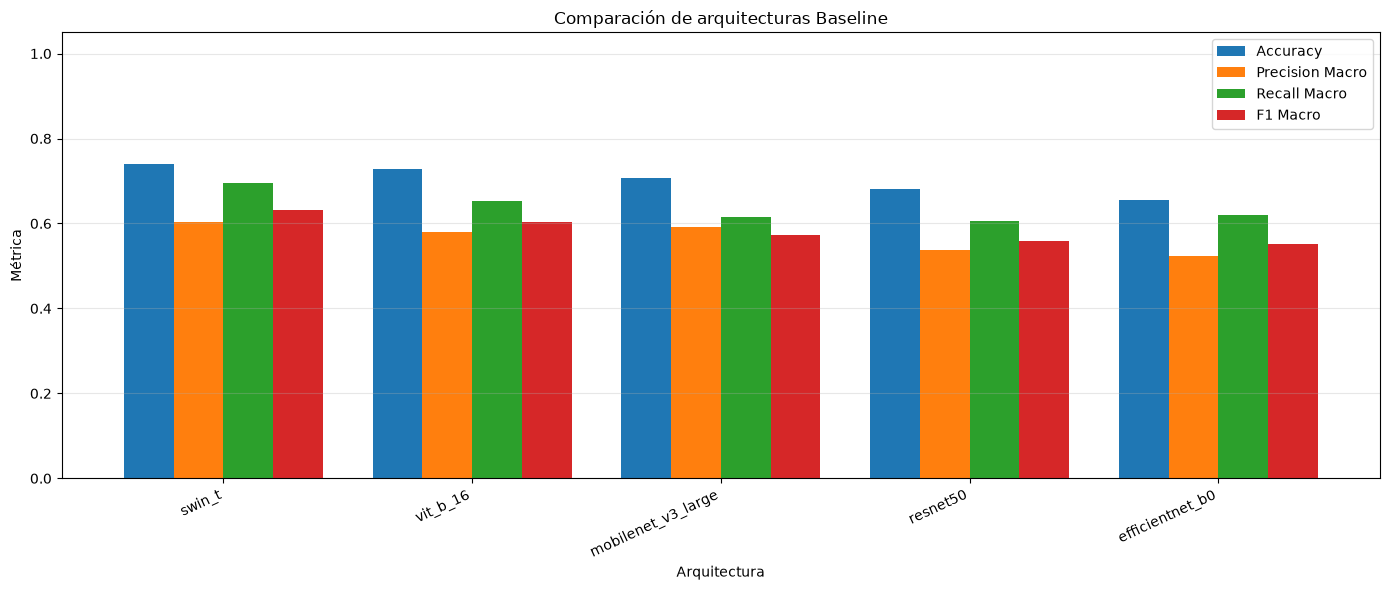

In [30]:
metrics_columns = [

    "accuracy",

    "precision_macro",

    "recall_macro",

    "f1_macro"

]

ax = df_baseline.set_index(

    "architecture"

)[metrics_columns].plot(

    kind="bar",

    figsize=(14, 6),

    width=0.8

)

ax.set_title(

    "Comparación de arquitecturas Baseline"

)

ax.set_xlabel("Arquitectura")

ax.set_ylabel("Métrica")

ax.set_ylim(0, 1.05)

ax.legend(

    [

        "Accuracy",

        "Precision Macro",

        "Recall Macro",

        "F1 Macro"

    ]

)

plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "baseline_metrics_comparison.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

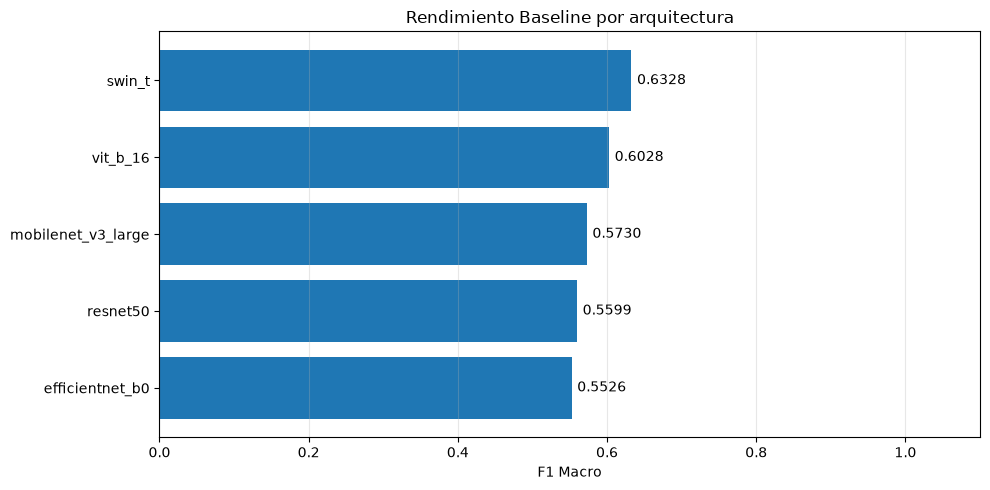

In [31]:
df_plot = df_baseline.sort_values(

    "f1_macro",

    ascending=True

)

fig, ax = plt.subplots(

    figsize=(10, 5)

)

bars = ax.barh(

    df_plot["architecture"],

    df_plot["f1_macro"]

)

ax.bar_label(

    bars,

    fmt="%.4f",

    padding=4

)

ax.set_xlim(0, 1.1)

ax.set_xlabel("F1 Macro")

ax.set_title(

    "Rendimiento Baseline por arquitectura"

)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "baseline_f1_ranking.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

,architecture,f1_macro_fe,f1_macro_ft,best_stage,finetuning_gain,finetuning_gain_pp
0,swin_t,0.6153,0.6328,partial_finetuning,0.0175,1.7541
1,vit_b_16,0.5681,0.6028,partial_finetuning,0.0347,3.4695
2,mobilenet_v3_large,0.5730,0.5467,feature_extraction,-0.0263,-2.6280
3,resnet50,0.5599,0.5330,feature_extraction,-0.0269,-2.6854
4,efficientnet_b0,0.5526,0.5350,feature_extraction,-0.0176,-1.7585


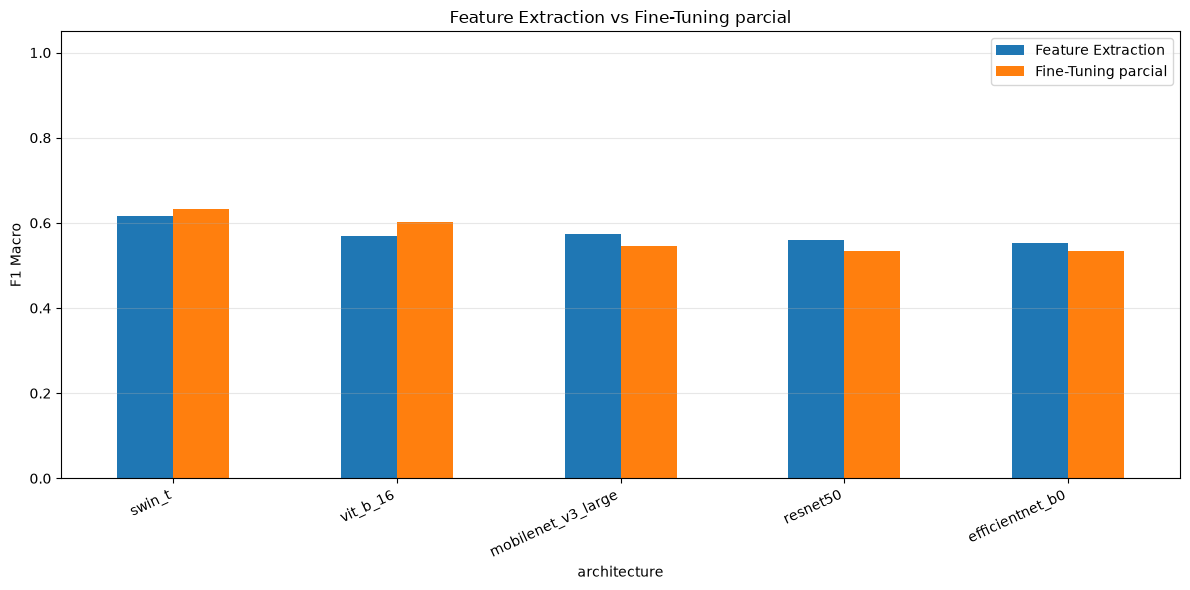

In [32]:
df_stage_comparison = df_baseline[

    [

        "architecture",

        "f1_macro_fe",

        "f1_macro_ft",

        "best_stage"

    ]

].copy()

df_stage_comparison["finetuning_gain"] = (

    df_stage_comparison["f1_macro_ft"]

    - df_stage_comparison["f1_macro_fe"]

)

df_stage_comparison["finetuning_gain_pp"] = (

    df_stage_comparison["finetuning_gain"]

    * 100

)

display(df_stage_comparison.round(4))

df_stage_comparison.to_csv(

    BASELINE_REPORTS_DIR
    / "stage_comparison.csv",

    index=False,

    encoding="utf-8-sig"

)

ax = df_stage_comparison.set_index(

    "architecture"

)[

    ["f1_macro_fe", "f1_macro_ft"]

].plot(

    kind="bar",

    figsize=(12, 6)

)

ax.set_title(

    "Feature Extraction vs Fine-Tuning parcial"

)

ax.set_ylabel("F1 Macro")

ax.set_ylim(0, 1.05)

ax.legend(

    [

        "Feature Extraction",

        "Fine-Tuning parcial"

    ]

)

plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "stage_comparison.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

In [33]:
all_histories = []

for model_name in df_baseline["architecture"]:

    history = pd.read_csv(

        BASELINE_REPORTS_DIR

        / model_name

        / "combined_history.csv"

    )

    history["architecture"] = model_name

    all_histories.append(history)

df_all_histories = pd.concat(

    all_histories,

    ignore_index=True

)

df_all_histories.to_csv(

    BASELINE_REPORTS_DIR
    / "all_training_histories.csv",

    index=False,

    encoding="utf-8-sig"

)

display(df_all_histories.head())

,epoch,train_accuracy,train_precision_macro,train_recall_macro,train_f1_macro,train_f1_weighted,train_balanced_accuracy,train_loss,train_seconds,train_num_samples,...,val_loss,val_seconds,val_num_samples,lr_classifier,epoch_seconds,is_best,stage,global_epoch,lr_backbone,architecture
0,1,0.621247,0.478560,0.559092,0.502742,0.647571,0.559092,1.112641,217.457132,12124,...,0.992648,71.465659,6063,0.0010,288.925054,True,feature_extraction,1,NaN,swin_t
1,2,0.685005,0.542384,0.628204,0.572143,0.704764,0.628204,0.974938,357.601713,12124,...,0.932645,129.583291,6063,0.0010,487.187590,True,feature_extraction,2,NaN,swin_t
2,3,0.692098,0.549259,0.637498,0.579439,0.711600,0.637498,0.948880,354.943045,12124,...,0.887145,132.255522,6063,0.0010,487.202768,True,feature_extraction,3,NaN,swin_t
3,1,0.706532,0.566389,0.657911,0.599350,0.724267,0.657911,0.915872,348.854719,12124,...,0.842262,112.366655,6063,0.0001,461.225703,True,partial_finetuning,4,0.00001,swin_t
4,2,0.721379,0.580605,0.668893,0.613059,0.737680,0.668893,0.863740,314.984806,12124,...,0.811618,112.409761,6063,0.0001,427.398324,True,partial_finetuning,5,0.00001,swin_t


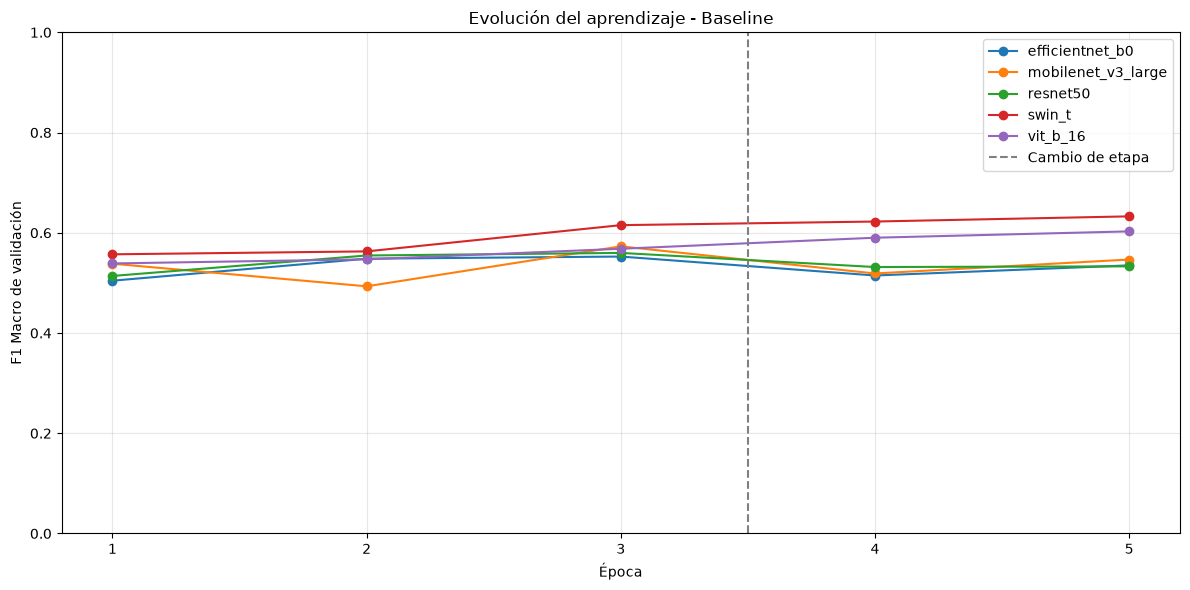

In [34]:
plt.figure(figsize=(12, 6))

for model_name, history in (

    df_all_histories.groupby("architecture")

):

    plt.plot(

        history["global_epoch"],

        history["val_f1_macro"],

        marker="o",

        label=model_name

    )

plt.axvline(

    x=3.5,

    linestyle="--",

    color="gray",

    label="Cambio de etapa"

)

plt.xlabel("Época")

plt.ylabel("F1 Macro de validación")

plt.title(

    "Evolución del aprendizaje - Baseline"

)

plt.xticks(range(1, 6))

plt.ylim(0, 1)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "validation_f1_curves.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

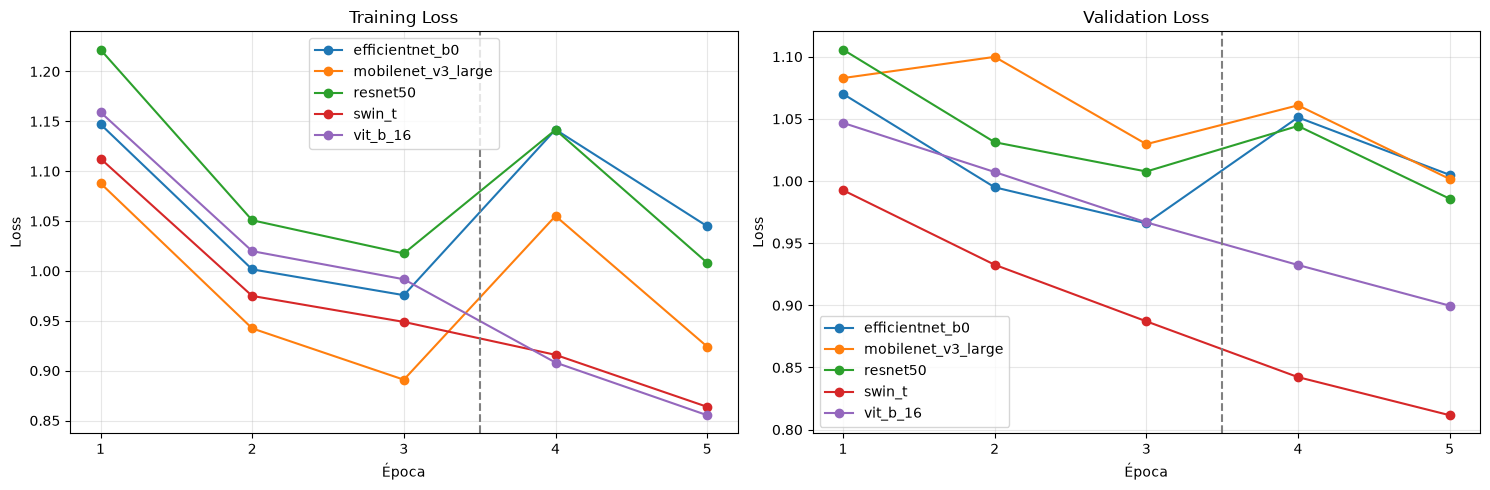

In [35]:
fig, axes = plt.subplots(

    1, 2,

    figsize=(15, 5)

)

for model_name, history in (

    df_all_histories.groupby("architecture")

):

    axes[0].plot(

        history["global_epoch"],

        history["train_loss"],

        marker="o",

        label=model_name

    )

    axes[1].plot(

        history["global_epoch"],

        history["val_loss"],

        marker="o",

        label=model_name

    )

axes[0].set_title("Training Loss")

axes[1].set_title("Validation Loss")

for ax in axes:

    ax.set_xlabel("Época")

    ax.set_ylabel("Loss")

    ax.set_xticks(range(1, 6))

    ax.axvline(

        3.5,

        linestyle="--",

        color="gray"

    )

    ax.legend()

    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "baseline_loss_curves.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

In [36]:
class_results = []

ordered_classes = sorted(

    CLASS_MAPPING,

    key=CLASS_MAPPING.get

)

for model_name in df_baseline["architecture"]:

    report = pd.read_csv(

        BASELINE_REPORTS_DIR

        / model_name

        / "classification_report.csv",

        index_col=0

    )

    for class_name in ordered_classes:

        class_results.append({

            "architecture": model_name,

            "class": class_name,

            "precision": report.loc[
                class_name, "precision"
            ],

            "recall": report.loc[
                class_name, "recall"
            ],

            "f1_score": report.loc[
                class_name, "f1-score"
            ],

            "support": report.loc[
                class_name, "support"
            ]

        })

df_class_results = pd.DataFrame(
    class_results
)

display(df_class_results.round(4))

df_class_results.to_csv(

    BASELINE_REPORTS_DIR
    / "baseline_class_metrics.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,class,precision,recall,f1_score,support
0,swin_t,bacterial_blight,0.3885,0.7240,0.5057,308.0
1,swin_t,brown_streak_disease,0.6319,0.6441,0.6380,621.0
2,swin_t,green_mottle,0.4841,0.6997,0.5723,676.0
3,swin_t,healthy,0.5523,0.6151,0.5820,730.0
4,swin_t,mosaic_disease,0.9596,0.7892,0.8661,3728.0
5,vit_b_16,bacterial_blight,0.3787,0.7045,0.4926,308.0
6,vit_b_16,brown_streak_disease,0.6039,0.5990,0.6015,621.0
7,vit_b_16,green_mottle,0.4476,0.6198,0.5199,676.0
8,vit_b_16,healthy,0.5220,0.5370,0.5294,730.0
9,vit_b_16,mosaic_disease,0.9448,0.8077,0.8709,3728.0


In [37]:
df_class_f1 = df_class_results.pivot(

    index="architecture",

    columns="class",

    values="f1_score"

)

df_class_f1 = df_class_f1.reindex(

    index=df_baseline["architecture"],

    columns=ordered_classes

)

display(df_class_f1.round(4))

df_class_f1.to_csv(

    BASELINE_REPORTS_DIR
    / "baseline_class_f1_matrix.csv",

    encoding="utf-8-sig"

)

class,bacterial_blight,brown_streak_disease,green_mottle,healthy,mosaic_disease
architecture,,,,,
swin_t,0.5057,0.6380,0.5723,0.5820,0.8661
vit_b_16,0.4926,0.6015,0.5199,0.5294,0.8709
mobilenet_v3_large,0.4563,0.4948,0.5537,0.5007,0.8593
resnet50,0.4602,0.5164,0.4740,0.5179,0.8310
efficientnet_b0,0.4655,0.4961,0.4867,0.5163,0.7984


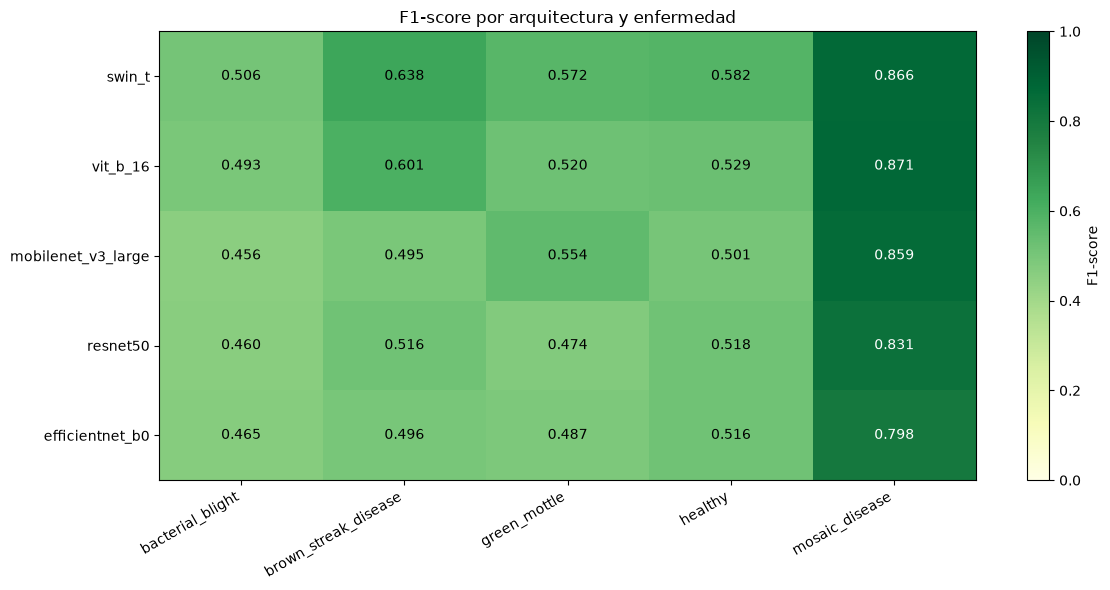

In [38]:
fig, ax = plt.subplots(

    figsize=(12, 6)

)

matrix = df_class_f1.to_numpy()

image = ax.imshow(

    matrix,

    cmap="YlGn",

    vmin=0,

    vmax=1,

    aspect="auto"

)

ax.set_xticks(

    range(len(df_class_f1.columns))

)

ax.set_xticklabels(

    df_class_f1.columns,

    rotation=30,

    ha="right"

)

ax.set_yticks(

    range(len(df_class_f1.index))

)

ax.set_yticklabels(

    df_class_f1.index

)

for i in range(matrix.shape[0]):

    for j in range(matrix.shape[1]):

        value = matrix[i, j]

        ax.text(

            j,

            i,

            f"{value:.3f}",

            ha="center",

            va="center",

            color=(
                "white"
                if value > 0.75
                else "black"
            )

        )

fig.colorbar(

    image,

    ax=ax,

    label="F1-score"

)

ax.set_title(

    "F1-score por arquitectura y enfermedad"

)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "baseline_class_heatmap.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

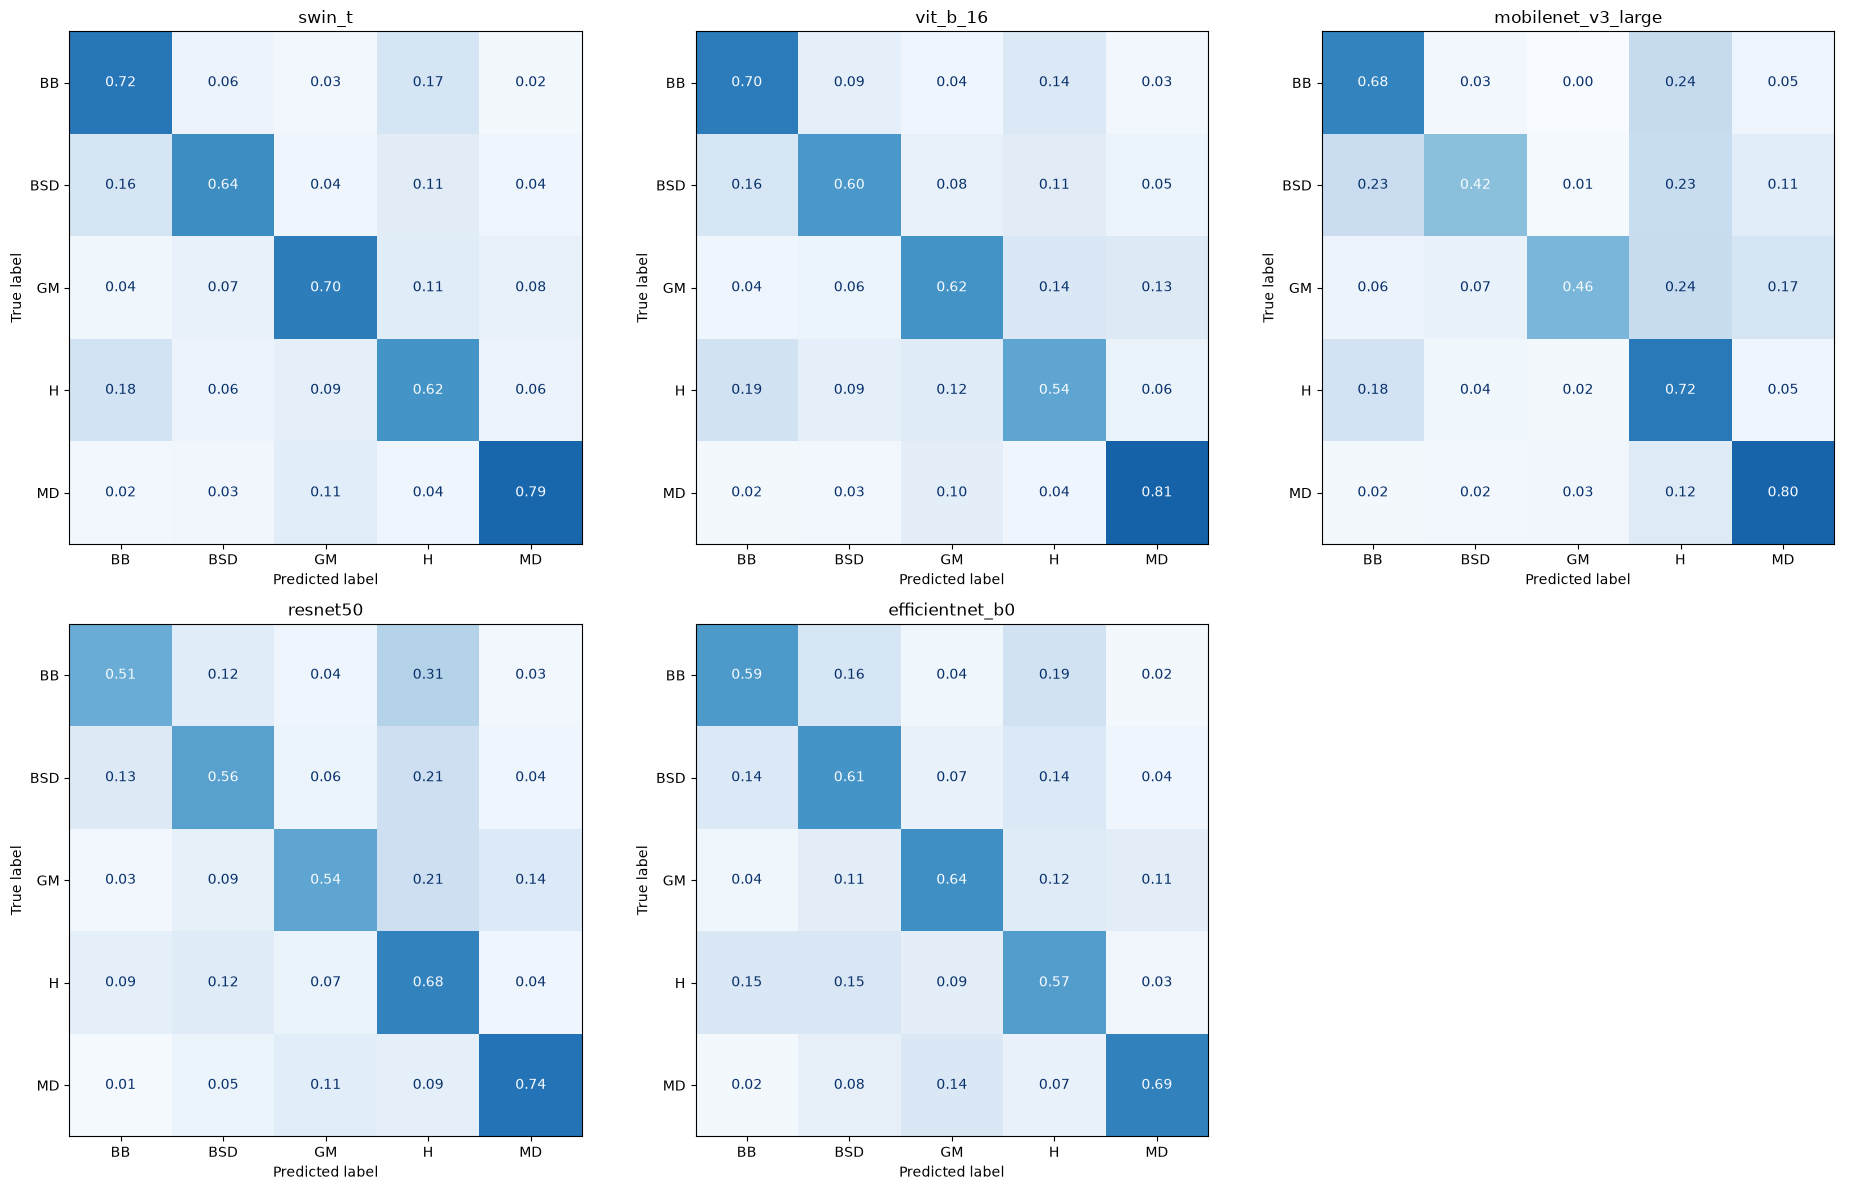

In [39]:
fig, axes = plt.subplots(

    2, 3,

    figsize=(19, 12)

)

axes = axes.flatten()

for ax, model_name in zip(

    axes,

    df_baseline["architecture"]

):

    detailed_metrics = load_json(

        BASELINE_REPORTS_DIR

        / model_name

        / "detailed_metrics.json"

    )

    matrix = np.asarray(

        detailed_metrics["confusion_matrix"],

        dtype=np.float64

    )

    row_sums = matrix.sum(

        axis=1,

        keepdims=True

    )

    normalized_matrix = np.divide(

        matrix,

        row_sums,

        out=np.zeros_like(matrix),

        where=row_sums != 0

    )

    display_matrix = ConfusionMatrixDisplay(

        confusion_matrix=normalized_matrix,

        display_labels=[

            "BB",

            "BSD",

            "GM",

            "H",

            "MD"

        ]

    )

    display_matrix.plot(

        ax=ax,

        cmap="Blues",

        values_format=".2f",

        colorbar=False

    )

    display_matrix.im_.set_clim(0, 1)

    ax.set_title(model_name)

for ax in axes[len(df_baseline):]:

    ax.axis("off")

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "baseline_confusion_matrices.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

In [40]:
df_computational_cost = df_baseline[

    [

        "architecture",

        "family",

        "total_parameters",

        "trainable_parameters_fe",

        "trainable_parameters_ft",

        "batch_size",

        "peak_memory_mib",

        "mean_epoch_minutes_fe",

        "mean_epoch_minutes_ft",

        "total_minutes"

    ]

].copy()

df_computational_cost["parameters_millions"] = (

    df_computational_cost["total_parameters"]

    / 1e6

)

display(

    df_computational_cost.round(4)

)

df_computational_cost.to_csv(

    BASELINE_REPORTS_DIR
    / "baseline_computational_cost.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,family,total_parameters,trainable_parameters_fe,trainable_parameters_ft,batch_size,peak_memory_mib,mean_epoch_minutes_fe,mean_epoch_minutes_ft,total_minutes,parameters_millions
0,swin_t,Transformer,27523199,3845,14189237,4,389.2095,7.0184,7.4052,37.8482,27.5232
1,vit_b_16,Transformer,85802501,3845,14181125,4,647.4834,23.8092,9.3446,92.9311,85.8025
2,mobilenet_v3_large,CNN,4208437,1236485,2189365,16,169.6055,5.4491,4.4653,26.5931,4.2084
3,resnet50,CNN,23518277,10245,14974981,8,397.1177,4.6356,8.5318,34.1678,23.5183
4,efficientnet_b0,CNN,4013953,6405,1135797,16,182.4409,4.1559,4.2264,43.0784,4.0140


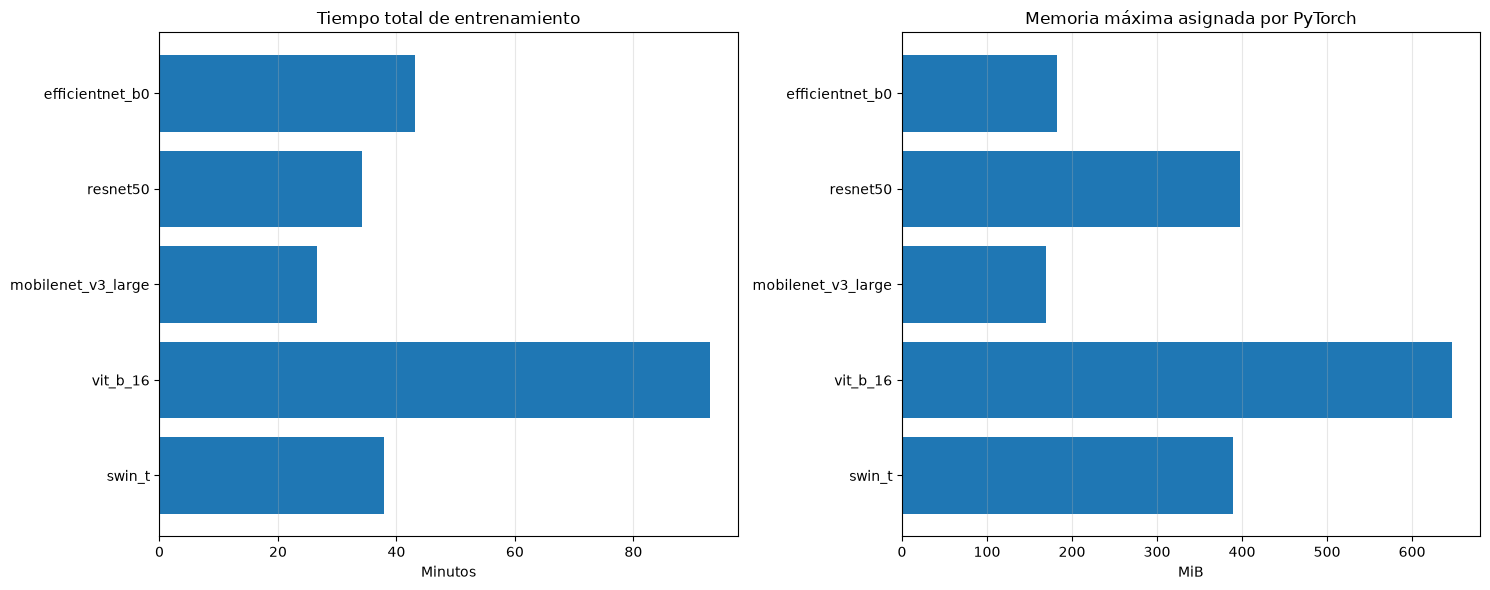

In [41]:
fig, axes = plt.subplots(

    1, 2,

    figsize=(15, 6)

)

axes[0].barh(

    df_computational_cost["architecture"],

    df_computational_cost["total_minutes"]

)

axes[0].set_title(

    "Tiempo total de entrenamiento"

)

axes[0].set_xlabel("Minutos")

axes[1].barh(

    df_computational_cost["architecture"],

    df_computational_cost["peak_memory_mib"]

)

axes[1].set_title(

    "Memoria máxima asignada por PyTorch"

)

axes[1].set_xlabel("MiB")

for ax in axes:

    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "baseline_computational_cost.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

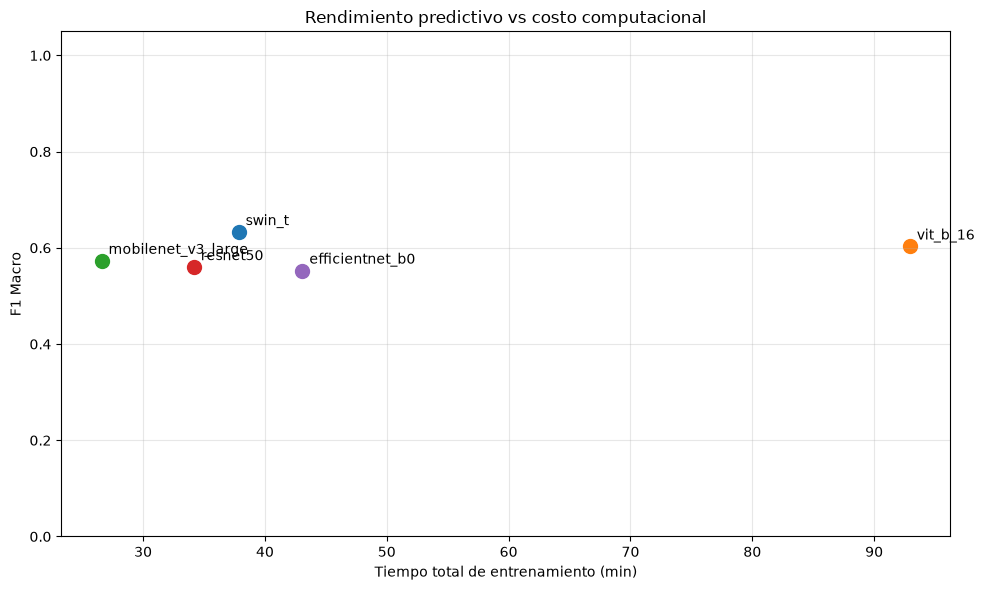

In [42]:
fig, ax = plt.subplots(

    figsize=(10, 6)

)

for _, row in df_baseline.iterrows():

    ax.scatter(

        row["total_minutes"],

        row["f1_macro"],

        s=100

    )

    ax.annotate(

        row["architecture"],

        (

            row["total_minutes"],

            row["f1_macro"]

        ),

        xytext=(5, 5),

        textcoords="offset points"

    )

ax.set_xlabel(

    "Tiempo total de entrenamiento (min)"

)

ax.set_ylabel("F1 Macro")

ax.set_title(

    "Rendimiento predictivo vs costo computacional"

)

ax.set_ylim(0, 1.05)

ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    BASELINE_REPORTS_DIR
    / "performance_vs_cost.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

In [43]:
df_optimizer_steps = df_baseline[

    [

        "architecture",

        "expected_optimizer_steps",

        "skipped_optimizer_steps",

        "skipped_steps_pct"

    ]

].copy()

df_optimizer_steps["actual_optimizer_steps"] = (

    df_optimizer_steps["expected_optimizer_steps"]

    - df_optimizer_steps["skipped_optimizer_steps"]

)

display(df_optimizer_steps.round(4))

df_optimizer_steps.to_csv(

    BASELINE_REPORTS_DIR
    / "baseline_optimizer_steps.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,expected_optimizer_steps,skipped_optimizer_steps,skipped_steps_pct,actual_optimizer_steps
0,swin_t,1895,0,0.0,1895
1,vit_b_16,1895,-1137,-60.0,3032
2,mobilenet_v3_large,1895,-2653,-140.0,4548
3,resnet50,1895,-2653,-140.0,4548
4,efficientnet_b0,1895,-2653,-140.0,4548


In [44]:
df_amp_warnings = df_all_histories[

    df_all_histories[
        "train_skipped_steps_pct"
    ] > 1.0

][

    [

        "architecture",

        "stage",

        "epoch",

        "train_expected_optimizer_steps",

        "train_optimizer_steps",

        "train_skipped_steps_pct",

        "train_amp_scale"

    ]

]

if df_amp_warnings.empty:

    print(

        "No se detectaron épocas que "

        "superen el umbral de alerta AMP."

    )

else:

    print(

        "Se detectaron épocas que "

        "requieren revisión."

    )

    display(df_amp_warnings)

df_amp_warnings.to_csv(

    BASELINE_REPORTS_DIR
    / "amp_warnings.csv",

    index=False,

    encoding="utf-8-sig"

)

No se detectaron épocas que superen el umbral de alerta AMP.


In [45]:
checkpoint_verification = []

for model_name in df_baseline["architecture"]:

    model_path = (

        BASELINE_MODELS_DIR

        / model_name

        / "baseline_model.pth"

    )

    checkpoint = torch.load(

        model_path,

        map_location="cpu",

        weights_only=True

    )

    assert checkpoint["architecture"] == model_name

    assert checkpoint["num_classes"] == NUM_CLASSES

    assert checkpoint["class_mapping"] == CLASS_MAPPING

    model = create_model(

        model_name=model_name,

        num_classes=NUM_CLASSES,

        pretrained=False,

        dropout=checkpoint["dropout"],

        mode="full_finetuning",

        device=DEVICE

    )

    model.load_state_dict(

        checkpoint["model_state_dict"],

        strict=True

    )

    model.eval()

    dummy_input = torch.randn(

        1,

        3,

        *preprocessing_config["image_size"],

        device=DEVICE

    )

    with torch.inference_mode():

        outputs = model(dummy_input)

    assert outputs.shape == (1, NUM_CLASSES)

    assert torch.isfinite(outputs).all()

    checkpoint_verification.append({

        "architecture": model_name,

        "checkpoint_size_mib": (

            model_path.stat().st_size

            / 1024**2

        ),

        "output_shape": str(
            tuple(outputs.shape)
        ),

        "status": "success"

    })

    del model
    del checkpoint
    del dummy_input
    del outputs

    release_memory()

df_checkpoint_verification = pd.DataFrame(

    checkpoint_verification

)

display(df_checkpoint_verification)

df_checkpoint_verification.to_csv(

    BASELINE_REPORTS_DIR
    / "checkpoint_verification.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,checkpoint_size_mib,output_shape,status
0,swin_t,105.267436,"(1, 5)",success
1,vit_b_16,327.359198,"(1, 5)",success
2,mobilenet_v3_large,16.237585,"(1, 5)",success
3,resnet50,90.011427,"(1, 5)",success
4,efficientnet_b0,15.579794,"(1, 5)",success


In [46]:
reference_predictions = None

prediction_verification = []

probability_columns = [

    f"prob_{class_name}"

    for class_name in ordered_classes

]

for model_name in df_baseline["architecture"]:

    df_predictions = pd.read_csv(

        BASELINE_REPORTS_DIR

        / model_name

        / "validation_predictions.csv"

    )

    assert len(df_predictions) == len(df_val)

    assert df_predictions["filepath"].is_unique

    assert set(

        df_predictions["filepath"]

    ) == set(df_val["filepath"])

    df_predictions = df_predictions.sort_values(

        "filepath"

    ).reset_index(drop=True)

    if reference_predictions is None:

        reference_predictions = (

            df_predictions[

                ["filepath", "y_true"]

            ].copy()

        )

    else:

        pd.testing.assert_frame_equal(

            reference_predictions,

            df_predictions[

                ["filepath", "y_true"]

            ]

        )

    probabilities = df_predictions[

        probability_columns

    ].to_numpy()

    assert np.isfinite(probabilities).all()

    assert (

        probabilities >= 0

    ).all()

    assert np.allclose(

        probabilities.sum(axis=1),

        1.0,

        atol=1e-5

    )

    prediction_verification.append({

        "architecture": model_name,

        "num_predictions": len(df_predictions),

        "num_classes": probabilities.shape[1],

        "status": "success"

    })

df_prediction_verification = pd.DataFrame(

    prediction_verification

)

display(df_prediction_verification)

df_prediction_verification.to_csv(

    BASELINE_REPORTS_DIR
    / "prediction_verification.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,num_predictions,num_classes,status
0,swin_t,6063,5,success
1,vit_b_16,6063,5,success
2,mobilenet_v3_large,6063,5,success
3,resnet50,6063,5,success
4,efficientnet_b0,6063,5,success


In [47]:
N_TRIALS = training_config[
    "optimization"
]["n_trials"]

MAX_RESOURCE = training_config[
    "optimization"
]["max_resource"]

df_hyperband_budget = df_baseline[

    [

        "architecture",

        "mean_epoch_minutes_fe",

        "mean_epoch_minutes_ft"

    ]

].copy()

df_hyperband_budget["n_trials"] = N_TRIALS

df_hyperband_budget["max_epochs_per_trial"] = (

    MAX_RESOURCE

)

df_hyperband_budget["max_hours_fe"] = (

    df_hyperband_budget["mean_epoch_minutes_fe"]

    * N_TRIALS

    * MAX_RESOURCE

    / 60

)

df_hyperband_budget["max_hours_ft"] = (

    df_hyperband_budget["mean_epoch_minutes_ft"]

    * N_TRIALS

    * MAX_RESOURCE

    / 60

)

display(

    df_hyperband_budget.round(3)

)

df_hyperband_budget.to_csv(

    BASELINE_REPORTS_DIR
    / "hyperband_budget_estimation.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,mean_epoch_minutes_fe,mean_epoch_minutes_ft,n_trials,max_epochs_per_trial,max_hours_fe,max_hours_ft
0,swin_t,7.018,7.405,12,9,12.633,13.329
1,vit_b_16,23.809,9.345,12,9,42.857,16.820
2,mobilenet_v3_large,5.449,4.465,12,9,9.808,8.038
3,resnet50,4.636,8.532,12,9,8.344,15.357
4,efficientnet_b0,4.156,4.226,12,9,7.481,7.607


In [48]:
baseline_summary = {

    "experiment": "baseline",

    "run_id": RUN_ID,

    "seed": SEED,

    "fold": CURRENT_FOLD,

    "architectures_expected": len(
        ARCHITECTURES
    ),

    "architectures_completed": len(
        df_baseline
    ),

    "train_images": len(df_train),

    "validation_images": len(df_val),

    "test_images": len(df_test),

    "test_used_for_training": False,

    "test_used_for_evaluation": False,

    "selection_metric": "f1_macro",

    "best_architecture": str(
        df_baseline.iloc[0]["architecture"]
    ),

    "best_f1_macro": float(
        df_baseline.iloc[0]["f1_macro"]
    ),

    "mean_f1_macro": float(
        df_baseline["f1_macro"].mean()
    ),

    "total_epochs": int(

        df_baseline["epochs_fe"].sum()

        + df_baseline["epochs_ft"].sum()

    ),

    "total_training_minutes": float(
        df_baseline["total_minutes"].sum()
    ),

    "amp_warning_epochs": len(
        df_amp_warnings
    ),

    "status": (

        "success"

        if len(df_baseline) == len(ARCHITECTURES)

        else "incomplete"

    )

}

save_json(

    baseline_summary,

    BASELINE_EXPERIMENTS_DIR
    / "baseline_summary.json"

)

display(baseline_summary)

{'experiment': 'baseline',
 'run_id': 'baseline_v1',
 'seed': 42,
 'fold': 1,
 'architectures_expected': 5,
 'architectures_completed': 5,
 'train_images': 12124,
 'validation_images': 6063,
 'test_images': 3210,
 'test_used_for_training': False,
 'test_used_for_evaluation': False,
 'selection_metric': 'f1_macro',
 'best_architecture': 'swin_t',
 'best_f1_macro': 0.632792340867123,
 'mean_f1_macro': 0.584213467350164,
 'total_epochs': 25,
 'total_training_minutes': 234.61850345000033,
 'amp_warning_epochs': 0,
 'status': 'success'}

In [49]:
assert len(df_baseline) == 5

assert set(

    df_baseline["architecture"]

) == set(ARCHITECTURES)

assert (

    df_baseline["status"] == "success"

).all()

assert (

    df_baseline["family"] == "CNN"

).sum() == 3

assert (

    df_baseline["family"] == "Transformer"

).sum() == 2

assert df_baseline[

    "f1_macro"

].between(0, 1).all()

assert np.isfinite(

    df_baseline["loss"]

).all()

assert (

    df_baseline["epochs_fe"] == 3

).all()

assert (

    df_baseline["epochs_ft"] == 2

).all()

assert len(df_checkpoint_verification) == 5

assert (

    df_checkpoint_verification["status"]

    == "success"

).all()

assert len(df_prediction_verification) == 5

assert (

    df_prediction_verification["status"]

    == "success"

).all()

assert len(df_class_results) == 25

assert baseline_summary["status"] == "success"

print("=" * 70)

print("FASE 2 - PARTE 4 COMPLETADA")

print("=" * 70)

print("Arquitecturas CNN: 3")

print("Arquitecturas Transformers: 2")

print("Modelos Baseline: 5/5")

print("Épocas ejecutadas: 25")

print("Checkpoints verificados: 5/5")

print("Predicciones verificadas: 5/5")

print("Test reservado: no utilizado")

print(

    "Mejor arquitectura:",

    baseline_summary["best_architecture"]

)

print(

    "Mejor F1 Macro:",

    baseline_summary["best_f1_macro"]

)

print(

    "Tiempo total (min):",

    baseline_summary["total_training_minutes"]

)

print(

    "Épocas con alertas AMP:",

    len(df_amp_warnings)

)

if not df_amp_warnings.empty:

    print(

        "ADVERTENCIA: revisar estabilidad AMP "

        "antes de iniciar Hyperband."

    )

FASE 2 - PARTE 4 COMPLETADA
Arquitecturas CNN: 3
Arquitecturas Transformers: 2
Modelos Baseline: 5/5
Épocas ejecutadas: 25
Checkpoints verificados: 5/5
Predicciones verificadas: 5/5
Test reservado: no utilizado
Mejor arquitectura: swin_t
Mejor F1 Macro: 0.632792340867123
Tiempo total (min): 234.61850345000033
Épocas con alertas AMP: 0


In [50]:
optimizer_audit = []

for model_name in ARCHITECTURES:

    history_path = (
        BASELINE_REPORTS_DIR
        / model_name
        / "combined_history.csv"
    )

    history = pd.read_csv(history_path)

    for _, row in history.iterrows():

        expected = int(
            row["train_expected_optimizer_steps"]
        )

        actual = int(
            row["train_optimizer_steps"]
        )

        optimizer_audit.append({

            "architecture": model_name,

            "stage": row["stage"],

            "epoch": int(row["epoch"]),

            "expected_steps": expected,

            "recorded_steps": actual,

            "step_ratio": (
                actual / expected
            ),

            "skipped_steps": (
                expected - actual
            ),

            "valid_counter": (
                0 <= actual <= expected
            ),

            "amp_scale": row["train_amp_scale"]

        })

df_optimizer_audit = pd.DataFrame(
    optimizer_audit
)

display(
    df_optimizer_audit.round(4)
)

,architecture,stage,epoch,expected_steps,recorded_steps,step_ratio,skipped_steps,valid_counter,amp_scale
0,mobilenet_v3_large,feature_extraction,1,379,758,2.0,-379,False,1024.0
1,mobilenet_v3_large,feature_extraction,2,379,758,2.0,-379,False,1024.0
2,mobilenet_v3_large,feature_extraction,3,379,758,2.0,-379,False,1024.0
3,mobilenet_v3_large,partial_finetuning,1,379,1137,3.0,-758,False,1024.0
4,mobilenet_v3_large,partial_finetuning,2,379,1137,3.0,-758,False,1024.0
5,efficientnet_b0,feature_extraction,1,379,758,2.0,-379,False,1024.0
6,efficientnet_b0,feature_extraction,2,379,758,2.0,-379,False,1024.0
7,efficientnet_b0,feature_extraction,3,379,758,2.0,-379,False,1024.0
8,efficientnet_b0,partial_finetuning,1,379,1137,3.0,-758,False,1024.0
9,efficientnet_b0,partial_finetuning,2,379,1137,3.0,-758,False,1024.0


In [51]:
df_optimizer_audit.to_csv(

    BASELINE_REPORTS_DIR
    / "optimizer_steps_audit.csv",

    index=False,

    encoding="utf-8-sig"

)

In [52]:
df_optimizer_audit_summary = (

    df_optimizer_audit

    .groupby(
        ["architecture", "stage"]
    )

    .agg(

        epochs=("epoch", "count"),

        expected_steps=(
            "expected_steps", "sum"
        ),

        recorded_steps=(
            "recorded_steps", "sum"
        ),

        mean_step_ratio=(
            "step_ratio", "mean"
        ),

        valid_epochs=(
            "valid_counter", "sum"
        )

    )

    .reset_index()

)

display(
    df_optimizer_audit_summary.round(4)
)

,architecture,stage,epochs,expected_steps,recorded_steps,mean_step_ratio,valid_epochs
0,efficientnet_b0,feature_extraction,3,1137,2274,2.0,0
1,efficientnet_b0,partial_finetuning,2,758,2274,3.0,0
2,mobilenet_v3_large,feature_extraction,3,1137,2274,2.0,0
3,mobilenet_v3_large,partial_finetuning,2,758,2274,3.0,0
4,resnet50,feature_extraction,3,1137,2274,2.0,0
5,resnet50,partial_finetuning,2,758,2274,3.0,0
6,swin_t,feature_extraction,3,1137,1137,1.0,3
7,swin_t,partial_finetuning,2,758,758,1.0,2
8,vit_b_16,feature_extraction,3,1137,2274,2.0,0
9,vit_b_16,partial_finetuning,2,758,758,1.0,2


In [53]:
from collections import Counter

adamw_audit = []

for model_name in ARCHITECTURES:

    for stage in [
        "feature_extraction",
        "partial_finetuning"
    ]:

        checkpoint_path = (

            BASELINE_MODELS_DIR
            / model_name
            / stage
            / "best.pth"

        )

        assert checkpoint_path.exists(), (
            f"Checkpoint no encontrado: "
            f"{checkpoint_path}"
        )

        checkpoint = torch.load(

            checkpoint_path,

            map_location="cpu",

            weights_only=True

        )

        checkpoint_epoch = int(
            checkpoint["epoch"]
        )

        optimizer_state = checkpoint[
            "optimizer_state_dict"
        ]

        parameter_steps = []

        for state in optimizer_state[
            "state"
        ].values():

            if "step" in state:

                step = state["step"]

                if torch.is_tensor(step):

                    step = step.item()

                parameter_steps.append(
                    int(step)
                )

        assert len(parameter_steps) > 0, (
            "No se encontraron contadores "
            "internos de AdamW."
        )

        step_distribution = Counter(
            parameter_steps
        )

        expected_steps = (
            checkpoint_epoch * 379
        )

        min_steps = min(parameter_steps)

        max_steps = max(parameter_steps)

        unique_steps = sorted(
            set(parameter_steps)
        )

        adamw_audit.append({

            "architecture": model_name,

            "stage": stage,

            "checkpoint_epoch": checkpoint_epoch,

            "expected_steps": expected_steps,

            "adamw_min_steps": min_steps,

            "adamw_max_steps": max_steps,

            "adamw_unique_steps": unique_steps,

            "parameter_tensors": len(
                parameter_steps
            ),

            "step_distribution": dict(
                step_distribution
            ),

            "step_ratio": (
                max_steps / expected_steps
            ),

            "valid_internal_steps": (
                min_steps == max_steps
                == expected_steps
            )

        })

        del checkpoint
        del optimizer_state

        gc.collect()

df_adamw_audit = pd.DataFrame(
    adamw_audit
)

display(
    df_adamw_audit.round(4)
)

,architecture,stage,checkpoint_epoch,expected_steps,adamw_min_steps,adamw_max_steps,adamw_unique_steps,parameter_tensors,step_distribution,step_ratio,valid_internal_steps
0,mobilenet_v3_large,feature_extraction,3,1137,1137,1137,[1137],4,{1137: 4},1.0,True
1,mobilenet_v3_large,partial_finetuning,2,758,758,758,[758],20,{758: 20},1.0,True
2,efficientnet_b0,feature_extraction,3,1137,1137,1137,[1137],2,{1137: 2},1.0,True
3,efficientnet_b0,partial_finetuning,2,758,758,758,[758],18,{758: 18},1.0,True
4,resnet50,feature_extraction,3,1137,1137,1137,[1137],2,{1137: 2},1.0,True
5,resnet50,partial_finetuning,2,758,758,758,[758],32,{758: 32},1.0,True
6,vit_b_16,feature_extraction,3,1137,1137,1137,[1137],2,{1137: 2},1.0,True
7,vit_b_16,partial_finetuning,2,758,758,758,[758],28,{758: 28},1.0,True
8,swin_t,feature_extraction,3,1137,1137,1137,[1137],2,{1137: 2},1.0,True
9,swin_t,partial_finetuning,2,758,758,758,[758],30,{758: 30},1.0,True


In [54]:
columns_to_display = [

    "architecture",

    "stage",

    "checkpoint_epoch",

    "expected_steps",

    "adamw_min_steps",

    "adamw_max_steps",

    "step_ratio",

    "valid_internal_steps"

]

display(

    df_adamw_audit[
        columns_to_display
    ].round(4)

)

,architecture,stage,checkpoint_epoch,expected_steps,adamw_min_steps,adamw_max_steps,step_ratio,valid_internal_steps
0,mobilenet_v3_large,feature_extraction,3,1137,1137,1137,1.0,True
1,mobilenet_v3_large,partial_finetuning,2,758,758,758,1.0,True
2,efficientnet_b0,feature_extraction,3,1137,1137,1137,1.0,True
3,efficientnet_b0,partial_finetuning,2,758,758,758,1.0,True
4,resnet50,feature_extraction,3,1137,1137,1137,1.0,True
5,resnet50,partial_finetuning,2,758,758,758,1.0,True
6,vit_b_16,feature_extraction,3,1137,1137,1137,1.0,True
7,vit_b_16,partial_finetuning,2,758,758,758,1.0,True
8,swin_t,feature_extraction,3,1137,1137,1137,1.0,True
9,swin_t,partial_finetuning,2,758,758,758,1.0,True


In [55]:
df_adamw_audit.to_csv(

    BASELINE_REPORTS_DIR
    / "adamw_internal_steps_audit.csv",

    index=False,

    encoding="utf-8-sig"

)

print(
    "Auditoría interna de AdamW guardada."
)

Auditoría interna de AdamW guardada.


In [56]:
assert len(df_adamw_audit) == 10

assert df_adamw_audit[
    "valid_internal_steps"
].all()

assert (
    df_adamw_audit["expected_steps"].sum()
    ==
    df_adamw_audit["adamw_max_steps"].sum()
)

for stage, expected_epochs in [
    ("feature_extraction", 3),
    ("partial_finetuning", 2)
]:

    stage_audit = df_adamw_audit[
        df_adamw_audit["stage"] == stage
    ]

    assert len(stage_audit) == 5

    assert (
        stage_audit["checkpoint_epoch"]
        == expected_epochs
    ).all()

print("Auditoría AdamW: SATISFACTORIA")
print("Checkpoints verificados: 10/10")
print("Cobertura: 25/25 épocas")
print("No se requiere reentrenamiento por esta incidencia.")

Auditoría AdamW: SATISFACTORIA
Checkpoints verificados: 10/10
Cobertura: 25/25 épocas
No se requiere reentrenamiento por esta incidencia.


In [57]:
df_verified_steps = (

    df_adamw_audit

    .groupby("architecture")

    .agg(

        verified_expected_steps=(
            "expected_steps", "sum"
        ),

        verified_actual_steps=(
            "adamw_max_steps", "sum"
        ),

        verified_checkpoints=(
            "valid_internal_steps", "sum"
        )

    )

    .reset_index()

)

df_verified_steps["verified_skipped_steps"] = (

    df_verified_steps["verified_expected_steps"]

    - df_verified_steps["verified_actual_steps"]

)

df_verified_steps["verified_skipped_pct"] = (

    df_verified_steps["verified_skipped_steps"]

    / df_verified_steps["verified_expected_steps"]

) * 100

df_verified_steps["verification_source"] = (
    "AdamW optimizer state"
)

display(df_verified_steps)

,architecture,verified_expected_steps,verified_actual_steps,verified_checkpoints,verified_skipped_steps,verified_skipped_pct,verification_source
0,efficientnet_b0,1895,1895,2,0,0.0,AdamW optimizer state
1,mobilenet_v3_large,1895,1895,2,0,0.0,AdamW optimizer state
2,resnet50,1895,1895,2,0,0.0,AdamW optimizer state
3,swin_t,1895,1895,2,0,0.0,AdamW optimizer state
4,vit_b_16,1895,1895,2,0,0.0,AdamW optimizer state


In [58]:
df_baseline_original = pd.read_csv(

    BASELINE_REPORTS_DIR
    / "baseline_results.csv"

)

df_baseline_verified = (
    df_baseline_original.copy()
)

# Conservar los contadores originales
df_baseline_verified = (
    df_baseline_verified.rename(

        columns={

            "expected_optimizer_steps":
                "original_expected_optimizer_steps",

            "skipped_optimizer_steps":
                "original_skipped_optimizer_steps",

            "skipped_steps_pct":
                "original_skipped_steps_pct"

        }

    )
)

# Incorporar los contadores verificados
df_baseline_verified = (
    df_baseline_verified.merge(

        df_verified_steps,

        on="architecture",

        how="left",

        validate="one_to_one"

    )
)

assert len(df_baseline_verified) == 5

assert df_baseline_verified[
    "verified_actual_steps"
].notna().all()

assert (
    df_baseline_verified[
        "verified_skipped_steps"
    ] == 0
).all()

df_baseline_verified.to_csv(

    BASELINE_REPORTS_DIR
    / "baseline_results_verified.csv",

    index=False,

    encoding="utf-8-sig"

)

display(

    df_baseline_verified[[

        "architecture",

        "f1_macro",

        "original_skipped_optimizer_steps",

        "verified_expected_steps",

        "verified_actual_steps",

        "verified_skipped_steps",

        "verified_skipped_pct"

    ]]

)

,architecture,f1_macro,original_skipped_optimizer_steps,verified_expected_steps,verified_actual_steps,verified_skipped_steps,verified_skipped_pct
0,mobilenet_v3_large,0.572956,-2653,1895,1895,0,0.0
1,efficientnet_b0,0.552595,-2653,1895,1895,0,0.0
2,resnet50,0.559891,-2653,1895,1895,0,0.0
3,vit_b_16,0.602832,-1137,1895,1895,0,0.0
4,swin_t,0.632792,0,1895,1895,0,0.0


In [59]:
from datetime import datetime

optimizer_incident = {

    "incident_id": "BASELINE_001",

    "timestamp": datetime.now().isoformat(),

    "phase": "phase_2_part_4",

    "experiment": "baseline",

    "run_id": RUN_ID,

    "description": (
        "Contabilización redundante de las "
        "actualizaciones del optimizador "
        "en versiones anteriores del pipeline."
    ),

    "affected_architectures": [

        "mobilenet_v3_large",

        "efficientnet_b0",

        "resnet50",

        "vit_b_16"

    ],

    "affected_epochs": 18,

    "total_epochs": 25,

    "verification": {

        "method": (
            "AdamW internal parameter step counters"
        ),

        "checkpoints_audited": 10,

        "valid_checkpoints": 10,

        "epochs_covered": 25,

        "expected_optimizer_steps": 9475,

        "verified_optimizer_steps": 9475,

        "verified_skipped_steps": 0

    },

    "resolution": {

        "original_reports_preserved": True,

        "verified_report_generated": True,

        "counter_validation_added": True,

        "model_weights_modified": False,

        "retraining_required_for_incident": False,

        "exact_historical_cause_verified": False

    },

    "limitations": [

        "Los contadores internos verifican la "
        "cantidad de actualizaciones, no toda "
        "la trayectoria de entrenamiento.",

        "Los tiempos computacionales no son "
        "estrictamente comparables debido a "
        "los cambios en el diagnóstico.",

        "La recuperación de ViT no garantiza "
        "reproducibilidad exacta bit a bit."

    ],

    "status": "resolved_for_baseline"

}

save_json(

    optimizer_incident,

    BASELINE_EXPERIMENTS_DIR
    / "optimizer_counter_incident.json"

)

print("Incidencia documentada correctamente.")

Incidencia documentada correctamente.


In [60]:
best_model = (

    df_baseline_verified

    .sort_values(
        "f1_macro",
        ascending=False
    )

    .iloc[0]

)

baseline_verified_summary = {

    "phase": "phase_2_part_4",

    "experiment": "baseline",

    "status": "completed_verified",

    "architectures_completed": 5,

    "cnn_architectures": 3,

    "transformer_architectures": 2,

    "total_epochs": 25,

    "optimizer_checkpoints_verified": 10,

    "expected_optimizer_steps": 9475,

    "verified_optimizer_steps": 9475,

    "verified_skipped_steps": 0,

    "best_architecture": str(
        best_model["architecture"]
    ),

    "best_f1_macro": float(
        best_model["f1_macro"]
    ),

    "total_minutes": float(

        df_baseline_verified[
            "total_minutes"
        ].sum()

    ),

    "test_used": False,

    "incident_documented": True,

    "retraining_required_for_incident": False

}

save_json(

    baseline_verified_summary,

    BASELINE_EXPERIMENTS_DIR
    / "baseline_summary_verified.json"

)

print("=" * 70)
print("FASE 2 - PARTE 4 COMPLETADA Y VERIFICADA")
print("=" * 70)

print("Modelos Baseline: 5/5")
print("Épocas completadas: 25/25")
print("Checkpoints AdamW verificados: 10/10")
print("Actualizaciones esperadas: 9475")
print("Actualizaciones verificadas: 9475")
print("Actualizaciones omitidas verificadas: 0")
print("Incidencia documentada: Sí")
print("Test reservado: no utilizado")

print(

    "Mejor arquitectura:",

    baseline_verified_summary[
        "best_architecture"
    ]

)

print(

    "Mejor F1 Macro:",

    baseline_verified_summary[
        "best_f1_macro"
    ]

)

FASE 2 - PARTE 4 COMPLETADA Y VERIFICADA
Modelos Baseline: 5/5
Épocas completadas: 25/25
Checkpoints AdamW verificados: 10/10
Actualizaciones esperadas: 9475
Actualizaciones verificadas: 9475
Actualizaciones omitidas verificadas: 0
Incidencia documentada: Sí
Test reservado: no utilizado
Mejor arquitectura: swin_t
Mejor F1 Macro: 0.632792340867123


In [61]:
release_memory()

print("Memoria GPU liberada.")

Memoria GPU liberada.
